# Run Experiments using excel files

## Step 1: Create or select an excel file
You will find excel files in /src/configs/xlsx - information about the input options is here: https://github.com/timisbusy/TemporalOrganizationOfShortTermElectricityMarkets
Note that not all features are supported with excel inputs at this time.

## Step 2: Run the code below, replacing the parameters in the TestExperiment.RunBasic() function

## Step 3: Find results in /results/{timestamp}_{experiment name}
You will find a link at the bottom of the code output. More information about output data can be found at https://github.com/timisbusy/TemporalOrganizationOfShortTermElectricityMarkets and in excel files under "Interpretation."

In [31]:
include("src/lib/experiments/test_experiment.jl")

# parameter 1: experiment name
# parameter 2: location of experiment xlsx file
TestExperiment.RunBasic("fixed_36", "src/configs/xlsx/experiments/Fixed36.xlsx")

println("done")

1793636314_fixed_36
Any[Dict{Symbol, Any}(:lookAheadDistance => 0, :clockTimeBegin => 12, :overrideMTU1Restriction => false, :enforceRampRates => true, :optimizationWindow => 36, :name => "Fixed1of24", :timePeriodsPerDay => 24, :clearingInterval => 24), Dict{Symbol, Any}(:lookAheadDistance => 0, :clockTimeBegin => 13, :overrideMTU1Restriction => false, :enforceRampRates => true, :optimizationWindow => 35, :name => "Fixed2of24", :timePeriodsPerDay => 24, :clearingInterval => 24), Dict{Symbol, Any}(:lookAheadDistance => 0, :clockTimeBegin => 14, :overrideMTU1Restriction => false, :enforceRampRates => true, :optimizationWindow => 34, :name => "Fixed3of24", :timePeriodsPerDay => 24, :clearingInterval => 24), Dict{Symbol, Any}(:lookAheadDistance => 0, :clockTimeBegin => 15, :overrideMTU1Restriction => false, :enforceRampRates => true, :optimizationWindow => 33, :name => "Fixed4of24", :timePeriodsPerDay => 24, :clearingInterval => 24), Dict{Symbol, Any}(:lookAheadDistance => 0, :clockTimeBeg

# Post Analysis

This code block runs a post analysis comparing the results of two designs. You will need to update the `case_paths` to match your results directories. Results can be found in /results/post_analysis.


starting analysis: lead time
Fixed Horizon rows: 2590
Rolling Horizon rows: 3661
Transaction info for Fixed Horizon
gross_traded: 8×2 DataFrame
 Row │ Agent           Gross traded - Fixed Horizon [MWh]
     │ String          Float64
─────┼────────────────────────────────────────────────────
   1 │ 1D_HighBid                               4.86358e5
   2 │ 3G_Base                                  3.12685e5
   3 │ 6G_Wind                                  5.13372e5
   4 │ Storage                                  3.81909e5
   5 │ 4G_Shoulder                          70272.4
   6 │ 7G_Solar                                 2.08143e5
   7 │ 2D_ModerateBid                       74662.3
   8 │ 5G_Peak                                 18.8895
net_energy_contracted: 8×2 DataFrame
 Row │ Agent           Net Energy Contracted - Fixed Horizon [MWh]
     │ String          Float64
─────┼─────────────────────────────────────────────────────────────
   1 │ 1D_HighBid                                       

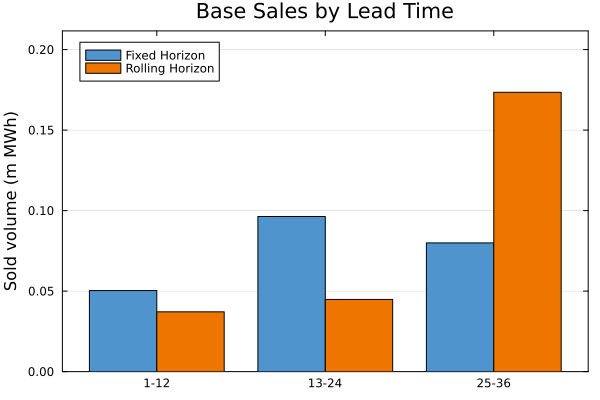

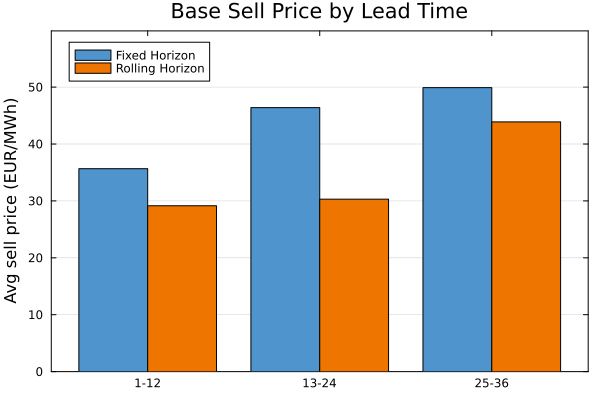

Volume for 1-12 in Fixed Horizon: 66832.6279319819Price for 1-12 in Fixed Horizon: 24.50123926192946Volume for 1-12 in Rolling Horizon: 63009.285041929914Price for 1-12 in Rolling Horizon: 23.508204288057975Volume for 13-24 in Fixed Horizon: 129109.62657291637Price for 13-24 in Fixed Horizon: 24.48440915534744Volume for 13-24 in Rolling Horizon: 90445.44716404693Price for 13-24 in Rolling Horizon: 29.287335643693442Volume for 25-36 in Fixed Horizon: 138893.2305882772Price for 25-36 in Fixed Horizon: 30.007137446487494Volume for 25-36 in Rolling Horizon: 248788.28142667795Price for 25-36 in Rolling Horizon: 23.991385206230376

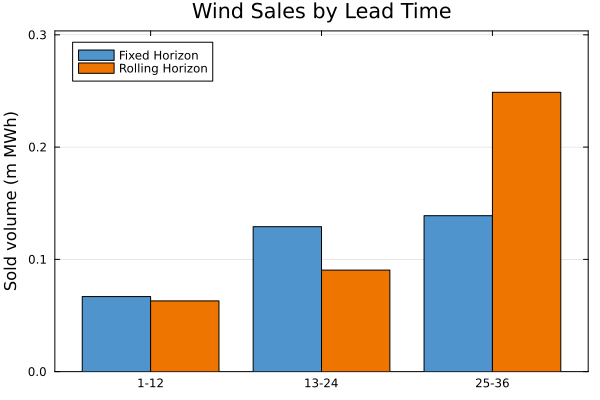

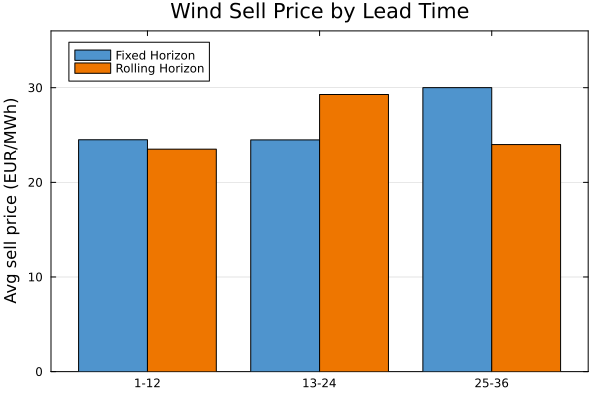

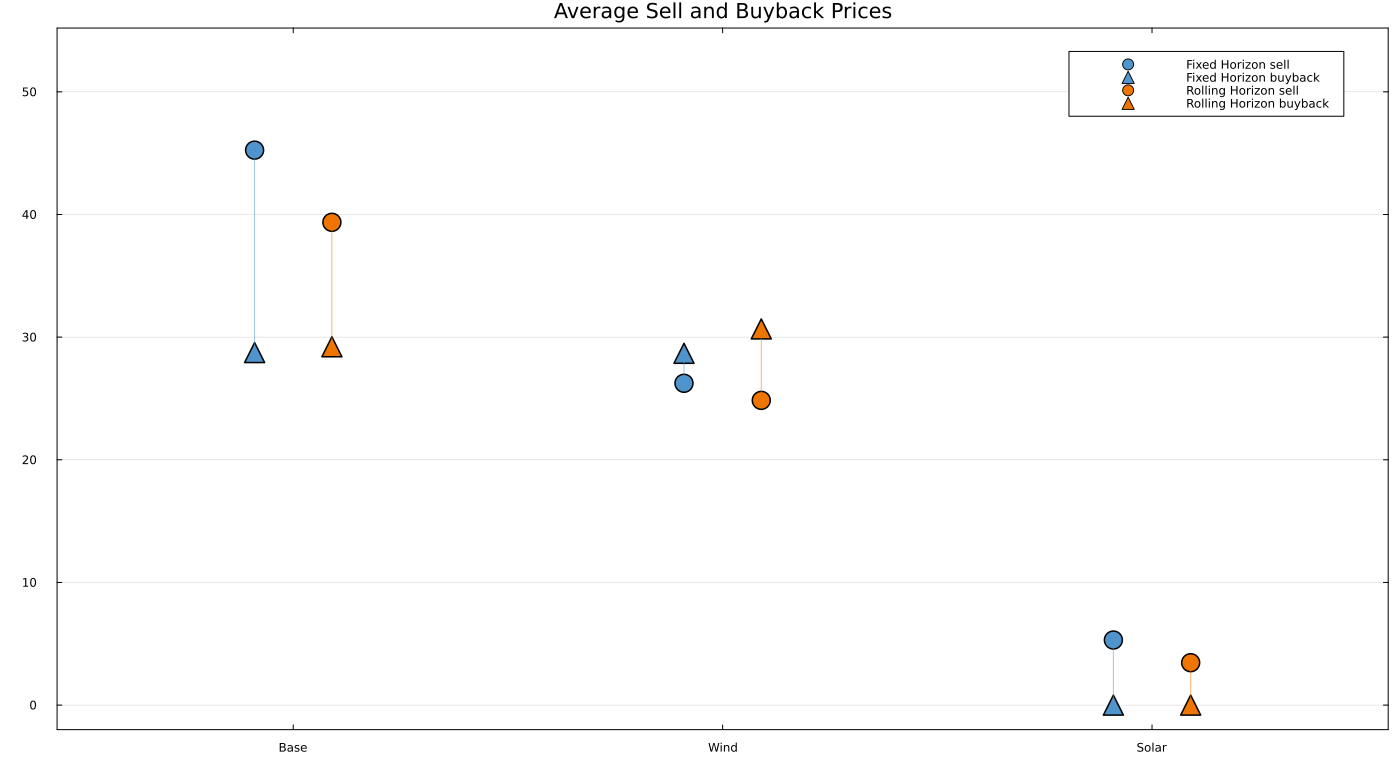

starting analysis: quantities by agent
get metrics for agent: 1D_HighBid AGENT_DEMAND
get metrics for agent: 2D_ModerateBid AGENT_DEMAND
get metrics for agent: 3G_Base AGENT_GENERATOR
get metrics for agent: 4G_Shoulder AGENT_GENERATOR
get metrics for agent: 5G_Peak AGENT_GENERATOR
get metrics for agent: 6G_Wind AGENT_GENERATOR
get metrics for agent: 7G_Solar AGENT_GENERATOR
SOC BEGIN = 0.0 SOC END = 1752.2948797059514
get metrics for agent: 1D_HighBid AGENT_DEMAND
get metrics for agent: 2D_ModerateBid AGENT_DEMAND
get metrics for agent: 3G_Base AGENT_GENERATOR
get metrics for agent: 4G_Shoulder AGENT_GENERATOR
get metrics for agent: 5G_Peak AGENT_GENERATOR
get metrics for agent: 6G_Wind AGENT_GENERATOR
get metrics for agent: 7G_Solar AGENT_GENERATOR
SOC BEGIN = 0.0 SOC END = 2061.830598206629
7×4 DataFrame
 Row │ Agent         Fixed Horizon Quantity (MWh)  Rolling Horizon Quantity (MWh)  Rolling Horizon vs Fixed Horizon % Diff 
     │ String        Float64                       Float64

In [ ]:
include("src/lib/post_analysis/post_analysis_runner.jl")


# include the case paths that you would like to compare
case_paths = Dict{String,String}(
    "Fixed Horizon" => "results/1793636314_fixed_36",
	"Rolling Horizon" => "results/1793636234_rolling_36",
)

PostAnalysisRunner.Run(case_paths;time_range=48:72)
# PostAnalysisRunner.Run(case_paths)
